# HT9046MX — From Raw Telemetry to Anomaly Review

## tl;dr

The evidence supports machine–module–state calibration, not one fleet-wide normal value. The current launch path is **Cold-qualified local profile → relationship-aware anomaly screening → technician confirmation → future supervised learning**. The historical hp180 model remains a benchmark only; the next release must be retrained and shadow-validated under the confirmed Cold-only contract.

**Presentation use:** Every figure is export-ready at 16:9 and is backed by a versioned project artefact. “Anomaly” means a persistent data deviation from the comparable local profile, not a named mechanical cause.

## 1. Scope, data and non-negotiable definitions

**Raw grain:** approximately one second. **Operational scoring grain:** five minutes, enriched with rolling/event features. **Cold-qualified baseline:** `Status=Compressor ON`, `Status_n=On`, `Busy=0`, `SV=Off`, after settling. `Busy=1` and `SV=On` are exclusions, not normal Cold examples.

The notebook reads only committed analytical outputs in `notebooks/outputs/`; it does not contact MySQL or modify a profile/model.

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'notebooks').exists(): ROOT = ROOT.parent
OUT = ROOT / 'notebooks' / 'outputs'
FIG = OUT / 'presentation_system_story'
FIG.mkdir(exist_ok=True)

BLUE, NAVY, CYAN, TEAL, ORANGE, RED, GREY, PALE = '#1565C0','#0B1F3A','#29B6F6','#00A6A6','#EF8A17','#D84343','#667085','#EAF3FB'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titleweight':'bold','axes.labelcolor':NAVY,'xtick.color':GREY,'ytick.color':GREY})
def save(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=220, bbox_inches='tight', facecolor='white'); plt.show()
def box(ax,x,y,w,h,text,fc=PALE,ec=BLUE,fs=11):
    p=FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.02,rounding_size=0.025',fc=fc,ec=ec,lw=1.6)
    ax.add_patch(p); ax.text(x+w/2,y+h/2,text,ha='center',va='center',color=NAVY,fontsize=fs,wrap=True)
def arrow(ax,a,b): ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=14,lw=1.5,color=GREY))

base = OUT/'ht9046mx_colab_analysis'
bench = OUT/'ht9046mx_phase7_benchmark_v2_hp180'
auto = OUT/'ht9046mx_autobootstrap'
comparability = pd.read_csv(base/'baseline_comparability.csv')
baseline = pd.read_csv(base/'baseline_stats.csv', dtype={'machine_number':str})
corr = pd.read_csv(base/'spearman_correlations.csv')
models = pd.read_csv(bench/'model_benchmark_summary.csv')
lifecycle = pd.read_csv(auto/'profile_lifecycle_status.csv')
split = pd.read_csv(OUT/'ht9046mx_ml_calibration'/'machine_split_manifest.csv', dtype={'machine_number':str})
nested = pd.read_csv(bench/'nested_temporal_split_manifest.csv', dtype={'machine_number':str})
params = json.loads((bench/'selected_hyperparameters.json').read_text(encoding='utf-8'))
benchmark_summary = json.loads((bench/'analysis_summary.json').read_text(encoding='utf-8'))
print('Sources loaded:', len(comparability), 'baseline comparisons,', len(corr), 'correlation rows,', len(lifecycle), 'profile records')

Sources loaded: 105 baseline comparisons, 4290 correlation rows, 262 profile records


## 2. Where the data came from — and which machines trained the benchmark

The verified primary snapshot contains **19 machines** and is the source used for the historical benchmark. The roles were fixed before the outer tests:

| Role | Machines | What the data may influence |
|---|---|---|
| Development + temporal + LOMO | **MX017, MX022, MX024, MX029, MX041, MX057, MX058, MX070, MX072, MX081, MX082, MX083** | Fit local profiles; train candidate models; inner validation selects parameters |
| Sparse/external test | **MX056, MX063, MX071, MX115, MX118, MX119, MX124** | Test transfer only; must not select features, parameters or thresholds |
| Incident replay only | **MX080 Module 6** | Verify that a known anomalous pattern produces strong score evidence; never used to tune the model |
| Later external intake / EDA | **MX007, MX012, MX017, MX025, MX057, MX070** | Coverage and data-quality analysis only; not silently added to the locked benchmark |

The next `cold-state-relationship-v2` release must declare a **new split manifest** before retraining. The table above describes the historical hp180 benchmark, not an authorization to reuse its threshold.

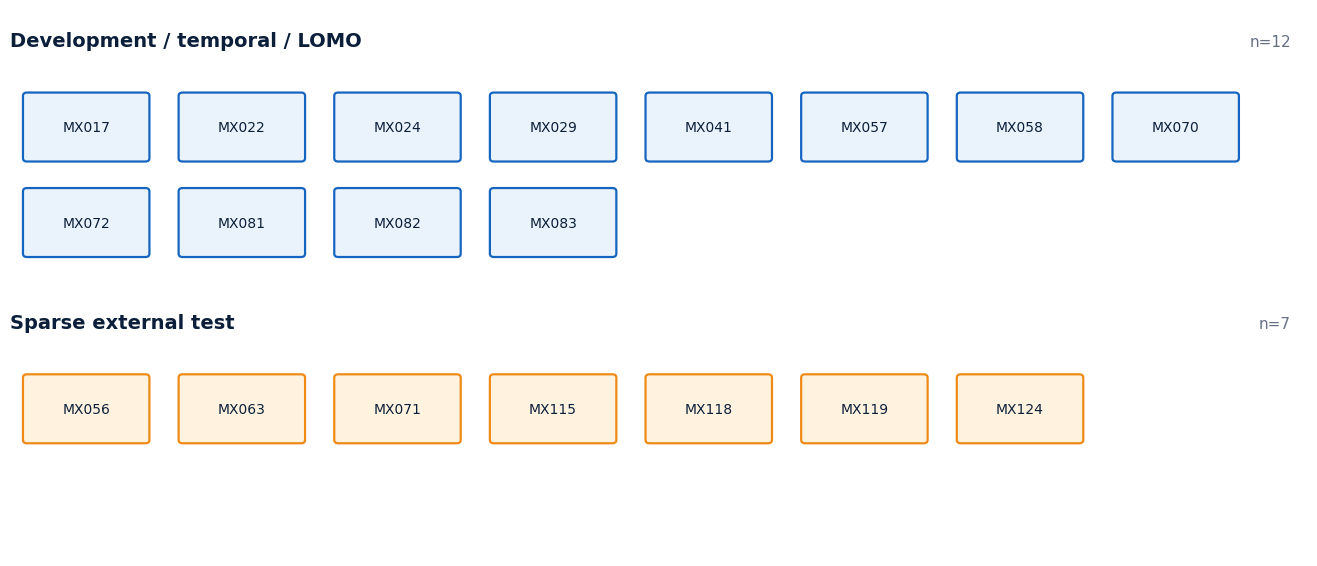

In [2]:
# Visual machine allocation for a presentation slide.
role_order = ['development_temporal_lomo', 'external_test']
role_label = {'development_temporal_lomo':'Development / temporal / LOMO', 'external_test':'Sparse external test'}
role_color = {'development_temporal_lomo':BLUE, 'external_test':ORANGE}
fig, axes = plt.subplots(2,1,figsize=(13.3,5.8))
for ax, role in zip(axes, role_order):
    machines = split.loc[split.role.eq(role),'machine_number'].str.zfill(3).tolist()
    ax.set_xlim(0,8); ax.set_ylim(0,2); ax.axis('off')
    ax.text(0,1.72,role_label[role],fontweight='bold',fontsize=14,color=NAVY)
    for i,m in enumerate(machines):
        x=.1+(i%8)*.96; y=.87-(i//8)*.72
        fill = '#EAF3FB' if role == 'development_temporal_lomo' else '#FFF3E0'
        box(ax,x,y,.74,.48,f'MX{m}',fill,role_color[role],10)
    ax.text(7.9,1.72,f'n={len(machines)}',ha='right',color=GREY)
save('00_machine_allocation.png')

### อ่านคำว่า “ใช้เทรน 12 เครื่อง” ให้ถูกต้อง

ข้อมูลชุด benchmark เดิมสร้าง feature ได้ **533,796 แถว**, ใช้ **33 features**, ครอบคลุม 6 model families โดยแบ่งงานดังนี้

1. **Inner temporal training:** ใช้อดีตของ 12 เครื่องกลุ่ม Development เพื่อ fit profile, imputer, scaler และ model candidate
2. **Inner validation:** ใช้ช่วงเวลาที่ใหม่กว่าช่วง train เพื่อเลือก hyperparameter เท่านั้น
3. **Calibration block:** ใช้ช่วงเวลาถัดมาเพื่อหา threshold ที่ percentile 99.5; ไม่ใช้ fit coefficient ของ model
4. **Outer temporal test:** ใช้อนาคตของเครื่องเดิมที่โมเดลไม่เคยเห็น เพื่อดูความเสถียรเมื่อเวลาเปลี่ยน
5. **LOMO จำนวน 12 folds:** ในแต่ละรอบกันเครื่องหนึ่งออกทั้งหมด เช่น fold MX057 จะ train จาก Development อีก 11 เครื่องและทดสอบ MX057 เท่านั้น แล้วสลับจนครบ 12 เครื่อง
6. **Sparse external test:** หลังล็อก feature, parameter และ threshold แล้ว จึงทดสอบ MX056, MX063, MX071, MX115, MX118, MX119 และ MX124 โดยห้ามย้อนกลับไปปรับ model จากผลกลุ่มนี้

ดังนั้นไม่มีเครื่อง test ใดถูกนำไป “แอบสอน” model ก่อนวัดผล และตัวเลขที่รายงานเป็น **screening/alert stability** ไม่ใช่ accuracy ของความเสียหาย เพราะยังไม่มี historical technician-confirmed fault labels.

> ข้อควรแยกให้ออก: benchmark `hp180` เดิมมีทั้ง `RUN_ON_SV_OFF` และ `RUN_ON_SV_ON` ภายใต้ profile แบบ Machine × Module × SV. กติกาหน้างานที่ยืนยันใหม่กำหนดให้ release ถัดไป `cold-state-relationship-v2` ใช้ Cold-qualified `SV=Off` เท่านั้น จึงต้อง retrain และหาค่า threshold ใหม่ก่อน launch; ห้ามนำ threshold เดิมไปใช้ตรง ๆ.

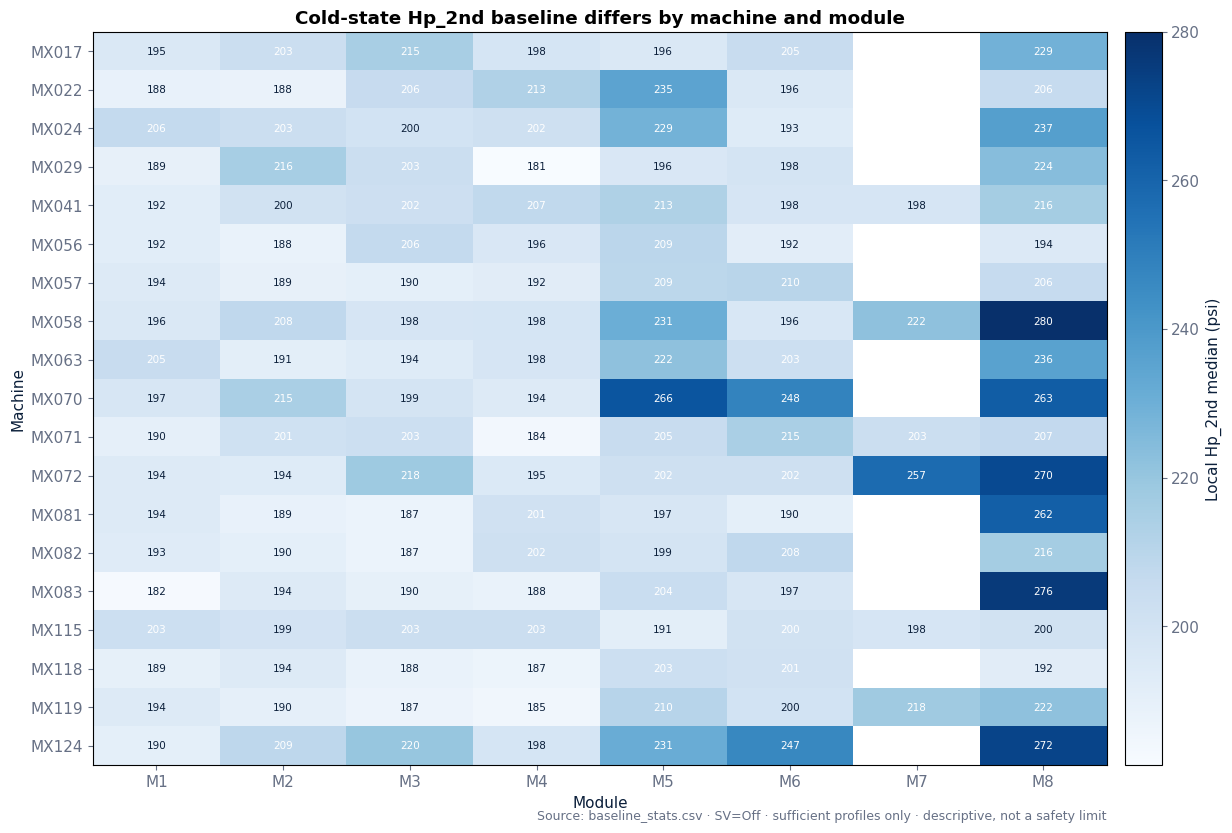

In [3]:
# Every cell is a local Hp_2nd median, not a fleet-wide normal threshold.
cold = baseline[(baseline.sv == 'Off') & baseline.sufficient_baseline].copy()
hp2_map = cold.pivot(index='machine_number', columns='module', values='hp2_median').sort_index()
fig, ax = plt.subplots(figsize=(13.3,8.4))
image_map = ax.imshow(hp2_map, aspect='auto', cmap='Blues')
ax.set_xticks(range(len(hp2_map.columns)), [f'M{m}' for m in hp2_map.columns])
ax.set_yticks(range(len(hp2_map.index)), [f'MX{str(m).zfill(3)}' for m in hp2_map.index])
for i in range(hp2_map.shape[0]):
    for j in range(hp2_map.shape[1]):
        value = hp2_map.iloc[i,j]
        if pd.notna(value):
            ax.text(j,i,f'{value:.0f}',ha='center',va='center',fontsize=7.5,
                    color='white' if value > np.nanmedian(hp2_map.to_numpy()) else NAVY)
bar = fig.colorbar(image_map, ax=ax, pad=.015); bar.set_label('Local Hp_2nd median (psi)')
ax.set(title='Cold-state Hp_2nd baseline differs by machine and module',xlabel='Module',ylabel='Machine')
ax.text(1.0,-.075,'Source: baseline_stats.csv · SV=Off · sufficient profiles only · descriptive, not a safety limit',
        transform=ax.transAxes,ha='right',color=GREY,fontsize=9)
save('00B_hp2_machine_module_baseline_map.png')

**วิธีอ่าน Heatmap:** ตัวเลขคือ median ของ `Hp_2nd` ภายใน profile ที่ผ่านเกณฑ์ข้อมูลของเครื่อง–โมดูลนั้น สีเข้มหมายถึงค่ากลางสูงกว่าเท่านั้น **ไม่ใช่สีบอกความเสียหาย**. ช่องว่างหมายถึงไม่มี sufficient baseline ใน artifact นี้ ไม่ใช่ค่า 0. ช่วง 180–230 psi เป็น field-reference สำหรับข้อมูลที่ผ่าน state gate และไม่ใช้แทน local profile.

### What one record means

Raw telemetry arrives at about one row per second. Each row contains the global Compressor `Status` and Module 1–8 fields. The analysis expands the wide row into a **machine × module × time** table. A minute is eligible only when its samples are complete and the discrete state is stable.

$$
\text{ColdQualified}_{m,k,t}=
\mathbb{1}[Status_t=ON]\,
\mathbb{1}[Status_{k,t}=On]\,
\mathbb{1}[Busy_{k,t}=0]\,
\mathbb{1}[SV_{k,t}=Off]\,
\mathbb{1}[\text{settled and complete}]
$$

Here, $m$ is the machine, $k$ the module and $t$ time. `Busy=1`, `MValveHome`, `ChangeValve`, negative valve commands, start/stop transients and mixed-state minutes are excluded from the normal Cold baseline.

## 3. The equations — explained in plain language

### 3.1 Local robust baseline

For feature $j$ in one machine–module–state profile, the centre is its median:

$$\tilde{x}_{j}=\operatorname{median}(x_{1j},\ldots,x_{nj})$$

The robust spread is the median absolute deviation (MAD):

$$MAD_j=\operatorname{median}\left(|x_{ij}-\tilde{x}_j|\right)$$

The relative feature sent to the fleet model is approximately:

$$rz_{ij}=\frac{x_{ij}-\tilde{x}_j}{\max(1.4826\,MAD_j,\;IQR_j/1.349,\;\epsilon_j)}$$

`rz = 0` means close to the local baseline; large positive or negative magnitude means far from that machine/module's normal. The scale floor $\epsilon_j$ prevents an almost constant sensor from creating infinite scores.

### 3.2 Physical relationships

$$\Delta P_{1,t}=Hp_{1st,t}-Lp_{1st,t}$$

$$\Delta P_{2,t}=Hp_{2nd,t}-Lp_{2nd,t}$$

These preserve the high–low pressure relationship. A coordinated shift can therefore be detected even when neither raw value alone crosses a universal limit.

### 3.3 Trend and response features

For a $w$-minute window, a simple slope is:

$$s^{(w)}_{x,t}=\frac{x_t-x_{t-w}}{w}$$

Valve-response change at lag $\ell$ is:

$$r^{(\ell)}_{x,t}=x_t-x_{t-\ell},\qquad
g^{(\ell)}_{x,t}=\frac{x_t-x_{t-\ell}}{\Delta Valve_{t,\ell}+\varepsilon}$$

The response features ask: “after the controller moved the expansion valve, did pressure/temperature respond like this local profile normally does?” They indicate association and timing—not causation.

## 4. What every model contributes

### Robust-MAD — transparent first line

Combines the strongest local robust deviations:

$$S_{MAD,t}=Q_q\left(|rz_{1,t}|,\ldots,|rz_{p,t}|\right)$$

It is easy to explain and acts as the minimum benchmark. If a complex model cannot improve operational stability over this baseline, it should not be promoted.

### ARX-Ridge — expected dynamic response

ชื่อ ARX สื่อถึงการใช้พฤติกรรมตามเวลาและ input ภายนอก เช่น Valve แต่ implementation ของ benchmark เขียนในรูป multi-output Ridge อย่างชัดเจนดังนี้:

$$Y_t=[rz(Hp_{2nd,t}),\;rz(Lp_{2nd,t})]$$

$$X_t=[\text{relative level, }\Delta P,\text{ stage gap, 15-min slope, 1/5-min response and Valve gain}]$$

โดย $X_t$ มี 31 predictors หลังแยก target สองตัวออกจาก feature ทั้งหมด 33 ตัว และหาค่าสัมประสิทธิ์ด้วย

$$\hat{Y}=\mathbf{1}b_0^T+X\hat{B},\qquad
(\hat{b}_0,\hat{B})=\arg\min_{b_0,B}\left(\|Y-\mathbf{1}b_0^T-XB\|_F^2+\alpha\|B\|_F^2\right)$$

คะแนนต่อเวลาคือ residual ที่มากที่สุดของแรงดันฝั่งที่สอง:

$$S_{ARX,t}=\max\left(|rz(Hp_{2nd,t})-\widehat{rz(Hp_{2nd,t})}|,\;|rz(Lp_{2nd,t})-\widehat{rz(Lp_{2nd,t})}|\right)$$

เพราะ target คือค่าจาก sensor ไม่ใช่ label “เสีย/ไม่เสีย” โมเดลนี้จึงเรียน expected relationship จากข้อมูลส่วนใหญ่ที่เป็น normal ได้ แม้ `Ridge` จะเป็น supervised regression ในเชิงคณิตศาสตร์ แต่ **ไม่ใช่ supervised fault classifier**. ชื่อ ARX-Ridge คงไว้ตาม artifact เดิม; สูตรด้านบนคือสิ่งที่โค้ด benchmark ทำจริง.

### PCA-SPE — correlation-subspace residual

After projecting the relative features onto the retained principal subspace:

$$SPE_t=\|z_t-P_KP_K^Tz_t\|_2^2$$

It detects combinations that do not follow the dominant normal covariance structure.

### Isolation Forest — multivariate isolation

Random trees repeatedly partition feature space. Unusual points require shorter average paths:

$$s(x,n)=2^{-E[h(x)]/c(n)}$$

It captures nonlinear interactions but is slower and harder to explain; `contamination` is not interpreted as a real fault rate.

### ECOD / COPOD — empirical tail evidence

ECOD measures how deep each feature lies in its empirical left/right tail; COPOD additionally uses copula dependence. They are useful parameter-light challengers when labels are absent.

### EWMA / CUSUM / Page-Hinkley — persistent drift

$$EWMA_t=\lambda x_t+(1-\lambda)EWMA_{t-1}$$

$$CUSUM_t^- = \min\left(0,CUSUM_{t-1}^- + x_t-\mu+k\right)$$

They accumulate small repeated changes, making them useful for slow degradation that does not look like a single spike.

### สรุปโมเดลทั้งหมดแบบไม่ใช้ศัพท์เทคนิค

- **Robust-MAD:** ถามว่า “sensor ตัวไหนห่างจากค่าปกติประจำเครื่องมากเกินไปหรือไม่” — อธิบายง่ายที่สุด
- **ARX-Ridge:** ถามว่า “เมื่อดู Valve, pressure ต่างระดับ, slope และ response ก่อนหน้าแล้ว Hp₂/Lp₂ ควรเป็นเท่าไร” — เหมาะกับความสัมพันธ์เชิงเวลาและยังอธิบาย residual ได้
- **PCA-SPE:** ถามว่า “ค่าหลายตัวกำลังเคลื่อนไปด้วยกันในรูปแบบเดิมหรือหลุดออกจาก pattern รวม”
- **Isolation Forest:** ถามว่า “combination นี้อยู่โดดเดี่ยวจากข้อมูลที่เคยเห็นเพียงใด” — จับ nonlinear pattern ได้ แต่ใช้ทรัพยากรและอธิบายยากกว่า
- **ECOD/COPOD:** ถามว่า “ค่าปัจจุบันอยู่ลึกในหางการแจกแจงเดี่ยว/ร่วมเพียงใด” — ใช้ parameter น้อย เหมาะเป็น challenger
- **EWMA/CUSUM/Page-Hinkley:** ถามว่า “มีการเปลี่ยนเล็ก ๆ แต่สะสมต่อเนื่องหรือไม่” — เหมาะกับ drift ที่ spike detector อาจมองข้าม

ระบบไม่ควรเชื่อ model ใด model หนึ่งเพียงเพราะ score สูงหนึ่งจุด แต่ควรรวม local context, relationship, persistence, data quality และ shadow evidence ก่อนเปิด alert.

## 5. Parameters actually used in the historical benchmark

| Model | Selected inner-validation parameter | Why it exists |
|---|---:|---|
| ARX-Ridge | $\alpha=0.1$ | Stabilizes correlated lag/pressure/valve coefficients |
| Isolation Forest | 200 trees, max samples 256, max features 0.7 | Balances nonlinear coverage and Server cost |
| PCA-SPE | retain 90% variance | Keeps the main normal relationship subspace |
| ECOD | feature quantile 0.90 | Focuses aggregation on stronger empirical tails |
| COPOD | top 5 contributions | Prevents many weak feature tails from dominating |
| Robust-MAD | feature quantile 0.80 | Transparent aggregate of larger local deviations |

These parameters were selected inside inner temporal validation. Outer temporal and LOMO results were not used to revise them. All must be reselected for the next Cold-only relationship-feature release.

In [4]:
display(pd.DataFrame([
    {'Machine':f'MX{str(r.machine_number).zfill(3)}','Source days':r.source_days,'Inner train':r.inner_train_days,'Inner validation':r.inner_validation_days,'Threshold calibration':r.calibration_days,'Untouched outer future':r.outer_temporal_days}
    for r in nested.itertuples()
]))

,Machine,Source days,Inner train,Inner validation,Threshold calibration,Untouched outer future
0,MX017,23,10,3,4,6
1,MX022,21,9,3,3,6
2,MX024,17,7,2,3,5
3,MX029,29,12,4,5,8
4,MX041,27,11,4,4,8
5,MX057,21,9,3,3,6
6,MX058,29,12,4,5,8
7,MX070,24,10,3,4,7
8,MX072,17,7,2,3,5
9,MX081,25,10,4,4,7


## 6. How a five-minute anomaly is produced

1. The one-second buffer calculates short response summaries.
2. The durable minute stream keeps level, differential, slope and lag evidence.
3. Every five minutes, features are transformed relative to the active local profile.
4. The locked detector outputs a raw anomaly score.
5. The threshold comes only from a separate past calibration block:

$$\tau=Q_{0.995}\left(S_t\mid t\in\text{past calibration}\right)$$

6. A raw flag is $a_t=\mathbb{1}[S_t>\tau]$.
7. The pilot persistence rule opens an alert after three consecutive qualified flags:

$$A_t=\mathbb{1}[a_t+a_{t-1}+a_{t-2}=3]$$

At five-minute cadence, the earliest persistent alert is therefore approximately **15 minutes** after a sustained pattern starts. A single short spike can remain visible as evidence without opening an operational alert.

## 7. How to read the result correctly

| System output | Meaning | What it does not mean |
|---|---|---|
| `Normal within this profile` | Passed data/state/profile gates and no persistent deviation | The equipment has no possible fault |
| `Anomaly detected` | Persistent pattern differs from the comparable local baseline | A specific cause has been diagnosed |
| `DATA_QUALITY` | Missing/stale/mixed-state/invalid input | Equipment anomaly |
| `INSUFFICIENT_PROFILE` | No approved comparable local profile | Safe to fall back silently to another machine |
| Technician `EQUIPMENT_ANOMALY` | Inspection found a real equipment anomaly for this alert | A named cause unless separately documented |
| Technician `NO_EQUIPMENT_ANOMALY` | Inspection did not find an equipment anomaly | Proof that the model is globally wrong |

The technician result is stored prospectively in MySQL, passes Label QA and later becomes a binary target for supervised training. `UNRESOLVED` and free-text notes remain audit evidence, not training targets.

## 2. Why a single baseline fails — observed machine × module variation

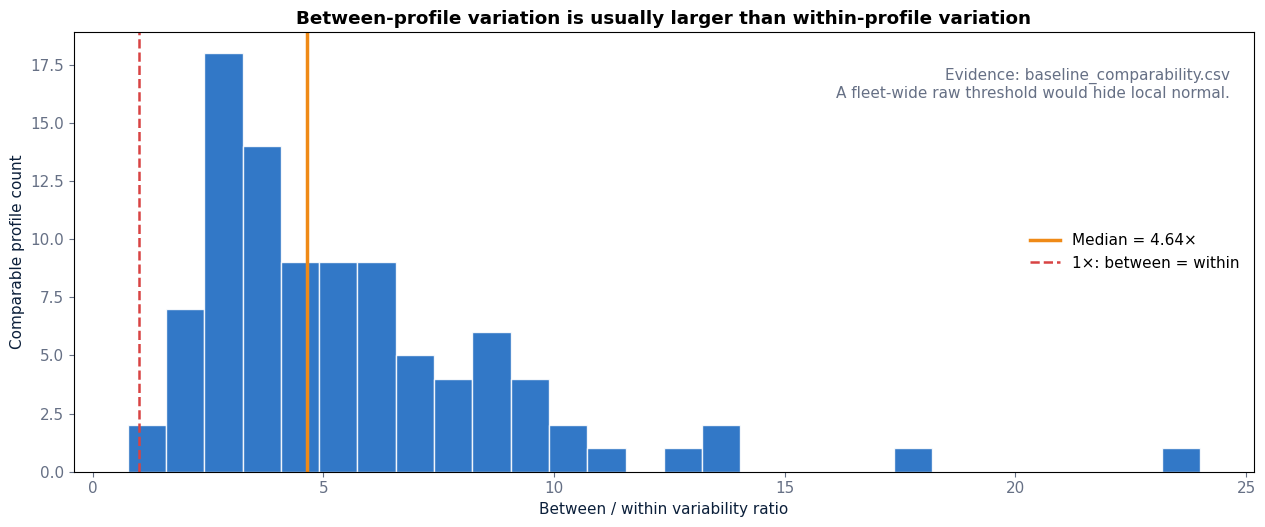

In [5]:
# The computed ratio compares between-profile median separation with within-profile variation.
ratio_col = [c for c in comparability.columns if 'ratio' in c.lower()][0]
v = pd.to_numeric(comparability[ratio_col], errors='coerce').dropna()
fig, ax = plt.subplots(figsize=(12.8,5.4)); ax.hist(v, bins=28, color=BLUE, alpha=.88, edgecolor='white')
ax.axvline(v.median(), color=ORANGE, lw=2.5, label=f'Median = {v.median():.2f}×')
ax.axvline(1, color=RED, ls='--', lw=1.8, label='1×: between = within')
ax.set(title='Between-profile variation is usually larger than within-profile variation', xlabel='Between / within variability ratio', ylabel='Comparable profile count')
ax.legend(frameon=False); ax.text(.98,.92,'Evidence: baseline_comparability.csv\nA fleet-wide raw threshold would hide local normal.',transform=ax.transAxes,ha='right',va='top',color=GREY)
save('01_baseline_comparability.png')

**Interpretation.** When the ratio exceeds one, two comparable machine/module profiles differ more from each other than their own normal spread. This is the quantitative reason for Auto-bootstrap / local calibration.

## 3. Correlation is conditional, not universal

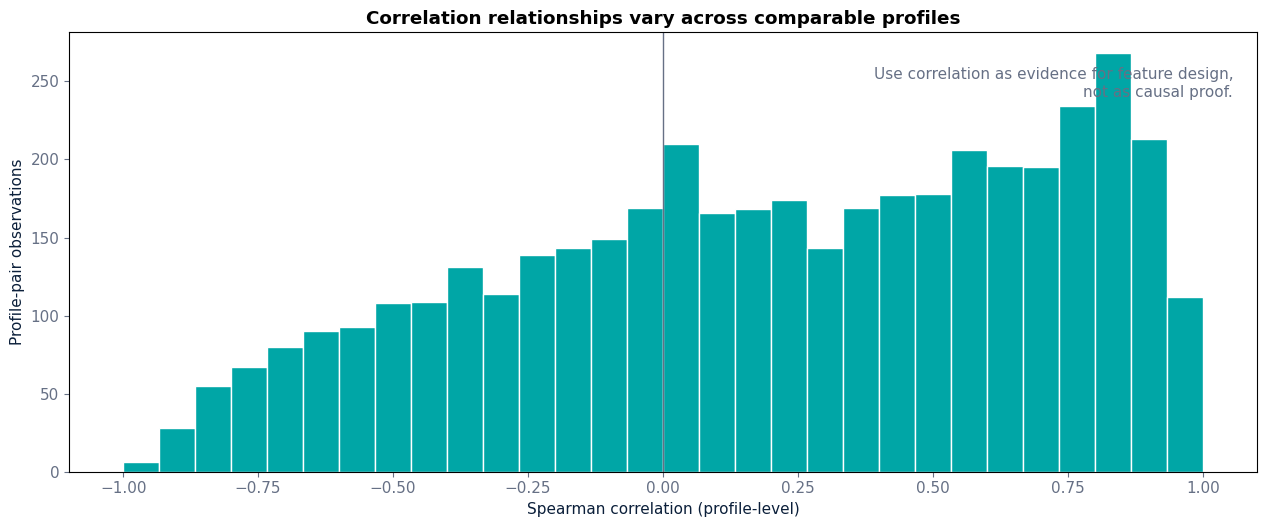

In [6]:
# Show distribution of validated Spearman relationships rather than averaging them into one fleet claim.
rho_col = next(c for c in corr.columns if c.lower() in {'rho','spearman_rho','correlation'} or 'spearman' in c.lower())
labels = [c for c in corr.columns if c not in {rho_col} and corr[c].dtype == object]
group = labels[0] if labels else None
top = corr.dropna(subset=[rho_col]).copy(); top[rho_col] = pd.to_numeric(top[rho_col])
fig, ax = plt.subplots(figsize=(12.8,5.4)); ax.hist(top[rho_col], bins=np.linspace(-1,1,31), color=TEAL, edgecolor='white')
ax.axvline(0,color=GREY,lw=1); ax.set(title='Correlation relationships vary across comparable profiles',xlabel='Spearman correlation (profile-level)',ylabel='Profile-pair observations')
ax.text(.98,.92,'Use correlation as evidence for feature design,\nnot as causal proof.',transform=ax.transAxes,ha='right',va='top',color=GREY)
save('02_conditional_correlations.png')

## 4. Automatic calibration profile — what it estimates

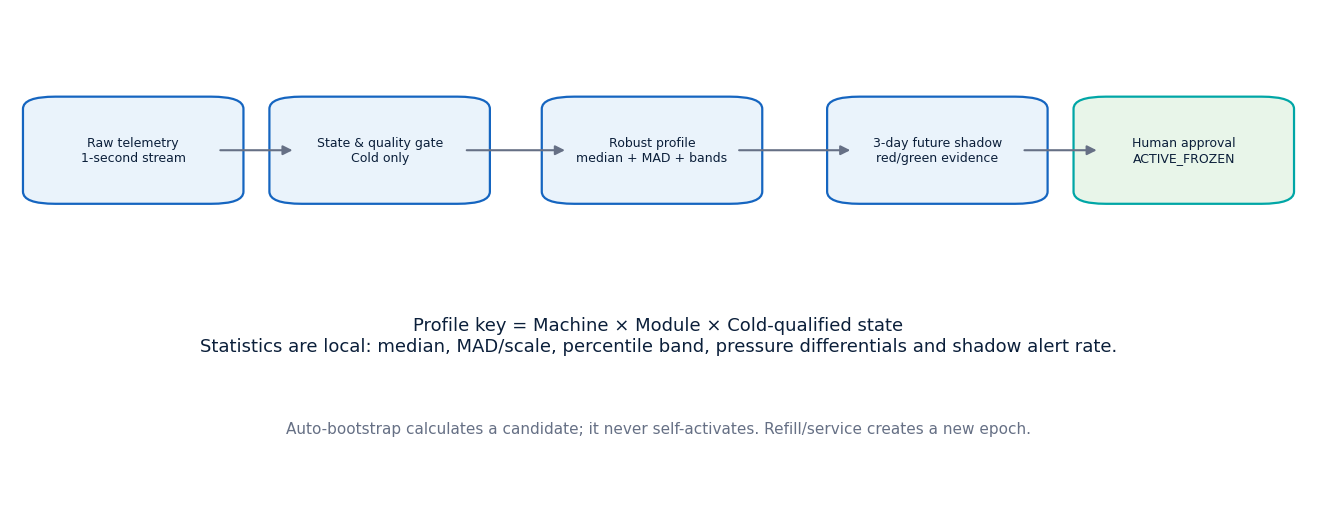

In [7]:
fig, ax=plt.subplots(figsize=(13.3,5.2)); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
steps=[('Raw telemetry\n1-second stream',.03,.62),('State & quality gate\nCold only',.22,.62),('Robust profile\nmedian + MAD + bands',.43,.62),('3-day future shadow\nred/green evidence',.65,.62),('Human approval\nACTIVE_FROZEN',.84,.62)]
for i,(t,x,y) in enumerate(steps): box(ax,x,y,.13,.18,t, PALE if i<4 else '#E8F5E9', BLUE if i<4 else TEAL,9); 
for i in range(4): arrow(ax,(steps[i][1]+.13,.71),(steps[i+1][1],.71))
ax.text(.5,.33,'Profile key = Machine × Module × Cold-qualified state\nStatistics are local: median, MAD/scale, percentile band, pressure differentials and shadow alert rate.',ha='center',va='center',fontsize=13,color=NAVY)
ax.text(.5,.13,'Auto-bootstrap calculates a candidate; it never self-activates. Refill/service creates a new epoch.',ha='center',color=GREY)
save('03_autocalibration_lifecycle.png')

## 5. Relationship-aware anomaly evidence

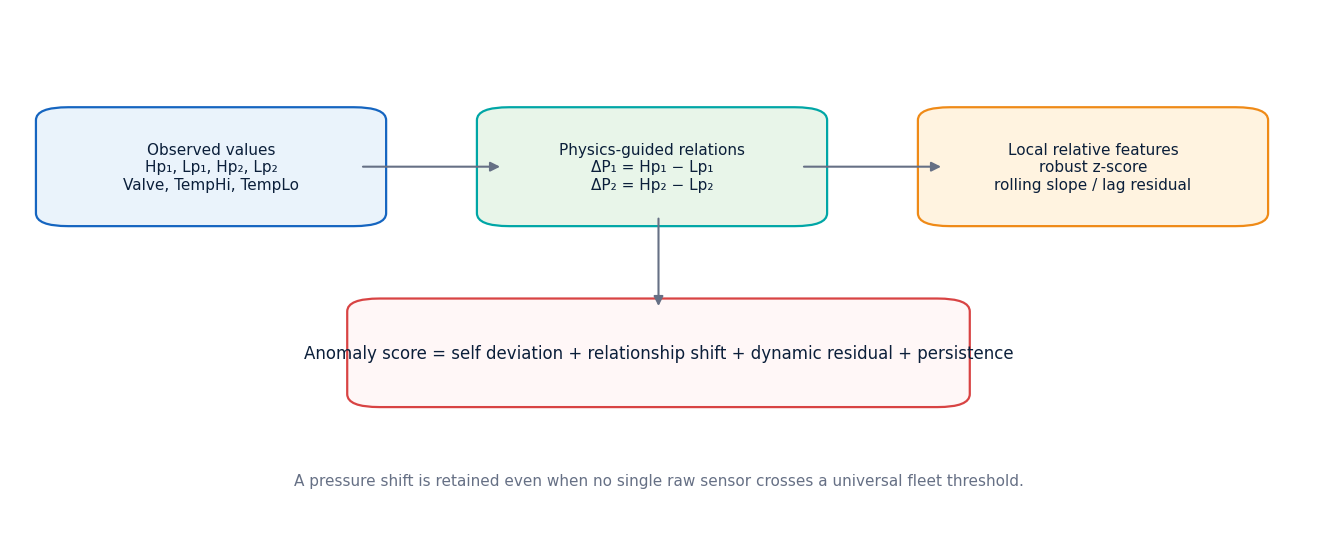

In [8]:
fig, ax=plt.subplots(figsize=(13.3,5.5)); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
box(ax,.04,.60,.23,.19,'Observed values\nHp₁, Lp₁, Hp₂, Lp₂\nValve, TempHi, TempLo')
box(ax,.38,.60,.23,.19,'Physics-guided relations\nΔP₁ = Hp₁ − Lp₁\nΔP₂ = Hp₂ − Lp₂', '#E8F5E9', TEAL)
box(ax,.72,.60,.23,.19,'Local relative features\nrobust z-score\nrolling slope / lag residual', '#FFF3E0', ORANGE)
arrow(ax,(.27,.695),(.38,.695)); arrow(ax,(.61,.695),(.72,.695))
box(ax,.28,.25,.44,.17,'Anomaly score = self deviation + relationship shift + dynamic residual + persistence', '#FFF7F7', RED,12)
arrow(ax,(.5,.60),(.5,.42)); ax.text(.5,.08,'A pressure shift is retained even when no single raw sensor crosses a universal fleet threshold.',ha='center',color=GREY)
save('04_relationship_features.png')

## 6. Why the model stack is shallow-first

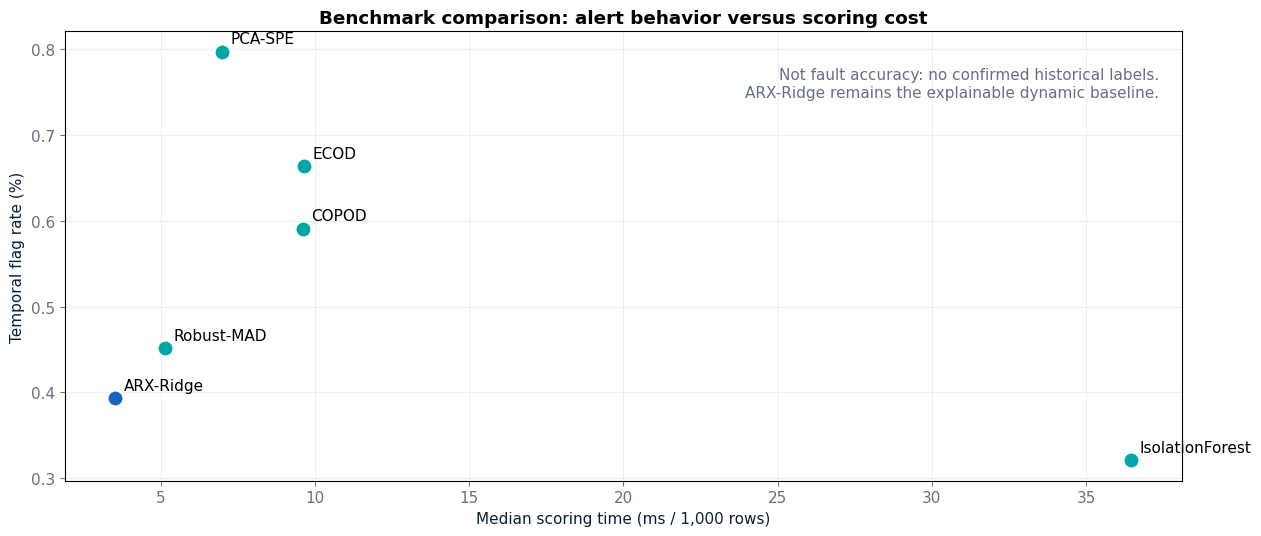

In [9]:
plot=models.copy(); plot['temporal_flag_pct_median']*=1; plot['score_ms_per_1000_rows_median']*=1
fig, ax=plt.subplots(figsize=(12.8,5.5))
for _,r in plot.iterrows(): ax.scatter(r['score_ms_per_1000_rows_median'],r['temporal_flag_pct_median'],s=120,color=BLUE if r['family']=='ARX-Ridge' else TEAL,edgecolor='white',zorder=3); ax.annotate(r['family'],(r['score_ms_per_1000_rows_median'],r['temporal_flag_pct_median']),xytext=(6,6),textcoords='offset points')
ax.set(title='Benchmark comparison: alert behavior versus scoring cost',xlabel='Median scoring time (ms / 1,000 rows)',ylabel='Temporal flag rate (%)'); ax.grid(alpha=.2)
ax.text(.98,.92,'Not fault accuracy: no confirmed historical labels.\nARX-Ridge remains the explainable dynamic baseline.',transform=ax.transAxes,ha='right',va='top',color=GREY)
save('05_model_tradeoff.png')

## 7. Validation protects against leakage

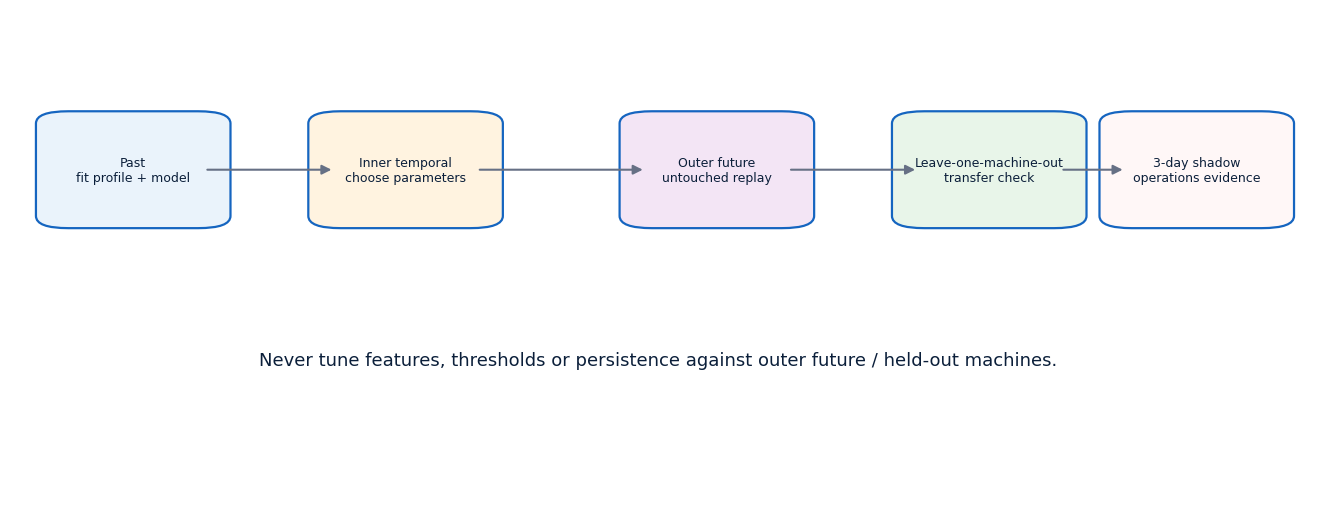

In [10]:
fig, ax=plt.subplots(figsize=(13.3,5.2)); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
items=[('Past\nfit profile + model',.04,'#EAF3FB'),('Inner temporal\nchoose parameters',.25,'#FFF3E0'),('Outer future\nuntouched replay',.49,'#F3E5F5'),('Leave-one-machine-out\ntransfer check',.70,'#E8F5E9'),('3-day shadow\noperations evidence',.86,'#FFF7F7')]
for i,(t,x,c) in enumerate(items): box(ax,x,.57,.11,.2,t,c,BLUE,9)
for i in range(4): arrow(ax,(items[i][1]+.11,.67),(items[i+1][1],.67))
ax.text(.5,.27,'Never tune features, thresholds or persistence against outer future / held-out machines.',ha='center',fontsize=13,color=NAVY)
save('06_validation_design.png')

## 8. Server data flow and technician learning loop

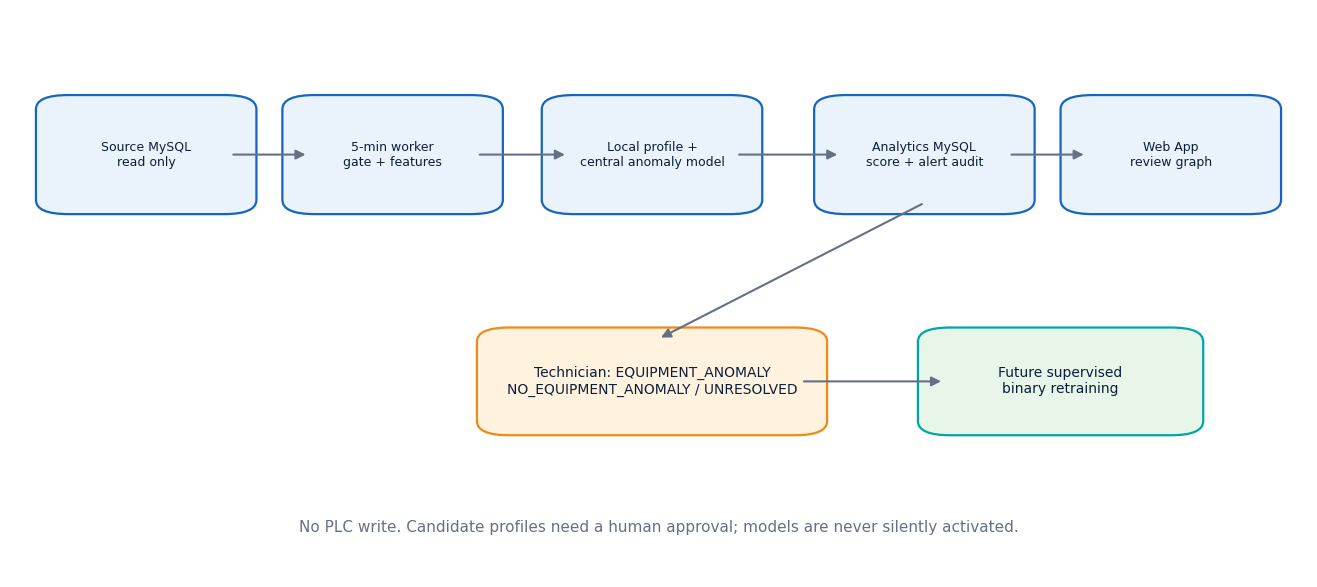

In [11]:
fig, ax=plt.subplots(figsize=(13.3,6)); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.axis('off')
top=[('Source MySQL\nread only',.04),('5-min worker\ngate + features',.23),('Local profile +\ncentral anomaly model',.43),('Analytics MySQL\nscore + alert audit',.64),('Web App\nreview graph',.83)]
for t,x in top: box(ax,x,.66,.13,.17,t,PALE,BLUE,9)
for i in range(4): arrow(ax,(top[i][1]+.13,.745),(top[i+1][1],.745))
box(ax,.38,.27,.23,.15,'Technician: EQUIPMENT_ANOMALY\nNO_EQUIPMENT_ANOMALY / UNRESOLVED','#FFF3E0',ORANGE,10)
box(ax,.72,.27,.18,.15,'Future supervised\nbinary retraining','#E8F5E9',TEAL,10)
arrow(ax,(.705,.66),(.5,.42)); arrow(ax,(.61,.345),(.72,.345))
ax.text(.5,.08,'No PLC write. Candidate profiles need a human approval; models are never silently activated.',ha='center',color=GREY)
save('07_server_workflow.png')

## 9. Launch plan and decision gates

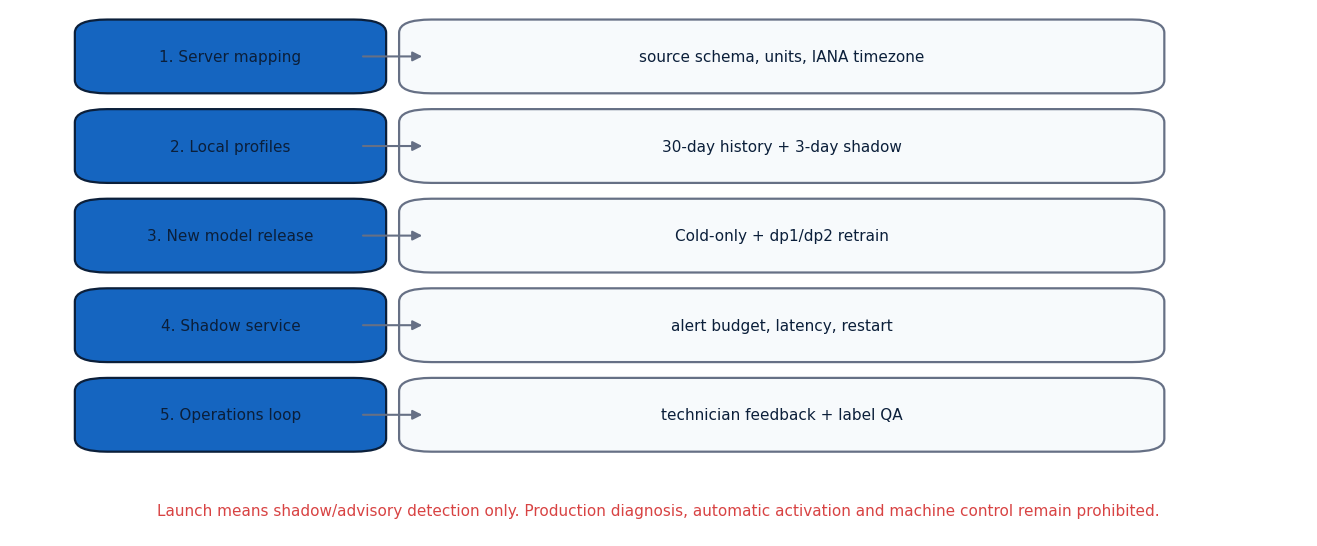

In [12]:
fig, ax=plt.subplots(figsize=(13.3,5.6)); ax.axis('off'); ax.set_xlim(0,1); ax.set_ylim(0,1)
lanes=[('1. Server mapping','source schema, units, IANA timezone'),('2. Local profiles','30-day history + 3-day shadow'),('3. New model release','Cold-only + dp1/dp2 retrain'),('4. Shadow service','alert budget, latency, restart'),('5. Operations loop','technician feedback + label QA')]
for i,(a,b) in enumerate(lanes):
 y=.86-i*.17; box(ax,.07,y,.2,.10,a,BLUE,NAVY,11); box(ax,.32,y,.55,.10,b,'#F7FAFC',GREY,11); arrow(ax,(.27,y+.05),(.32,y+.05))
ax.text(.5,.04,'Launch means shadow/advisory detection only. Production diagnosis, automatic activation and machine control remain prohibited.',ha='center',color=RED,fontsize=11)
save('08_launch_gates.png')

## Takeaways

1. **Baseline and relationships are local.** Verified comparability and correlation outputs show why the system must calibrate per machine/module/state.
2. **Auto-bootstrap is a controlled profile lifecycle, not automatic deployment.** It produces a reviewable candidate and a three-day future shadow graph.
3. **The model detects an anomaly in minutes, not a named fault.** Five-minute scoring plus persistence opens a data-derived `Anomaly detected` review.
4. **The new release must be retrained.** `cold-state-relationship-v2` uses confirmed Cold-only windows and `dp1/dp2`; hp180 is historical evidence only.
5. **Technician feedback is the bridge to supervised learning.** It provides prospective binary labels; free-text notes remain audit context, not model classes.